# SMS Spam Classification using SVM
Dataset: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset?resource=download

In [46]:
!pip -q install wordcloud nltk scikit-learn

In [47]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

True

## Upload dataset (`spam.csv`) downloaded from Kaggle.

In [48]:
from google.colab import files
uploaded = files.upload()

Saving spam.csv to spam (3).csv


In [49]:
# Load dataset and select only the relevant columns
df = pd.read_csv("spam.csv", encoding="latin-1", usecols=['v1', 'v2'])
df.columns = ['label', 'message']

# Strip any accidental leading/trailing whitespace
df['label'] = df['label'].str.strip()
df['message'] = df['message'].str.strip()

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
df.head()

Dataset shape: (5572, 2)
Duplicate rows: 414


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [50]:
print("===== Dataset Info =====")
df.info()

print("\n===== Missing Values =====")
print(df.isnull().sum())

print("\n===== Class Distribution =====")
dist_df = pd.DataFrame({
    'Count': df['label'].value_counts(),
    'Percentage (%)': (df['label'].value_counts(normalize=True) * 100).round(2)
})
print(dist_df)

===== Dataset Info =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

===== Missing Values =====
label      0
message    0
dtype: int64

===== Class Distribution =====
       Count  Percentage (%)
label                       
ham     4825           86.59
spam     747           13.41


## Exploratory Data Analysis

===== Average Structural Features: Ham vs. Spam =====
       char_count  word_count  digit_count  exclamation_count  question_count  \
label                                                                           
ham         70.99       14.20         0.30               0.17            0.28   
spam       138.82       23.85        15.76               0.73            0.23   

       currency_count  upper_ratio  
label                               
ham              0.00         0.06  
spam             0.44         0.11  


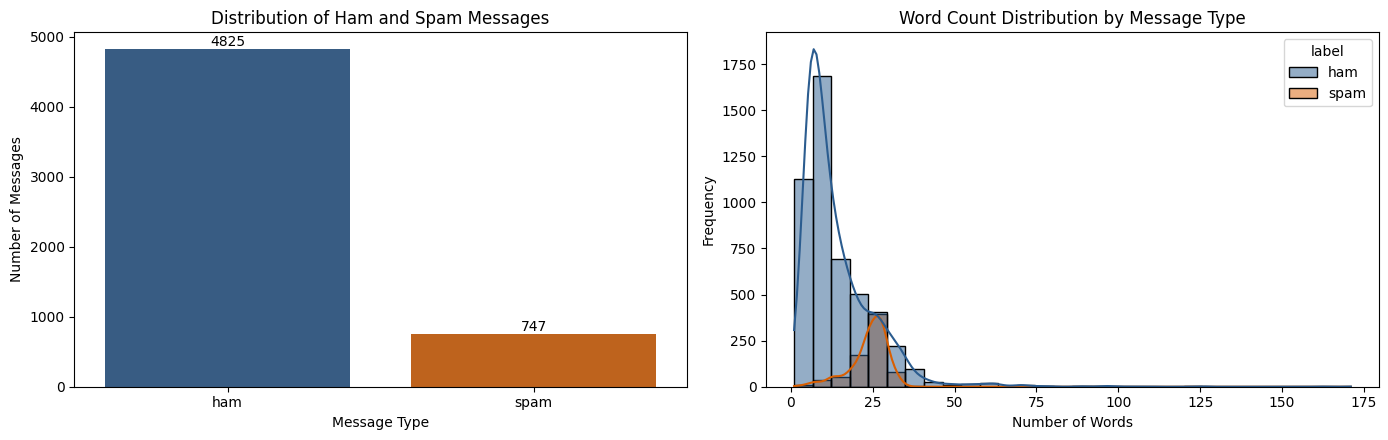

In [51]:
# Engineer structural features
df['char_count'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()
df['digit_count'] = df['message'].str.count(r'\d')
df['exclamation_count'] = df['message'].str.count('!')
df['question_count'] = df['message'].str.count(r'\?')
df['currency_count'] = df['message'].str.count(r'[£$€]')
df['upper_ratio'] = df['message'].str.findall(r'[A-Z]').str.len() / (df['char_count'] + 1)

# Show average feature values by class
feature_cols = [
    'char_count', 'word_count', 'digit_count',
    'exclamation_count', 'question_count', 'currency_count', 'upper_ratio'
]
print("===== Average Structural Features: Ham vs. Spam =====")
print(df.groupby('label')[feature_cols].mean().round(2))

# Plot Class Distribution and Word Count Distribution side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Countplot with exact bar labels
ax1 = sns.countplot(data=df, x='label', hue='label', palette=['#2b5c8f', '#d95f02'], legend=False, ax=axes[0])
axes[0].set_title('Distribution of Ham and Spam Messages')
axes[0].set_xlabel('Message Type')
axes[0].set_ylabel('Number of Messages')
for container in ax1.containers:
    ax1.bar_label(container)

# 2. Word Count Histogram
sns.histplot(
    data=df,
    x='word_count',
    hue='label',
    palette=['#2b5c8f', '#d95f02'],
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title('Word Count Distribution by Message Type')
axes[1].set_xlabel('Number of Words')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

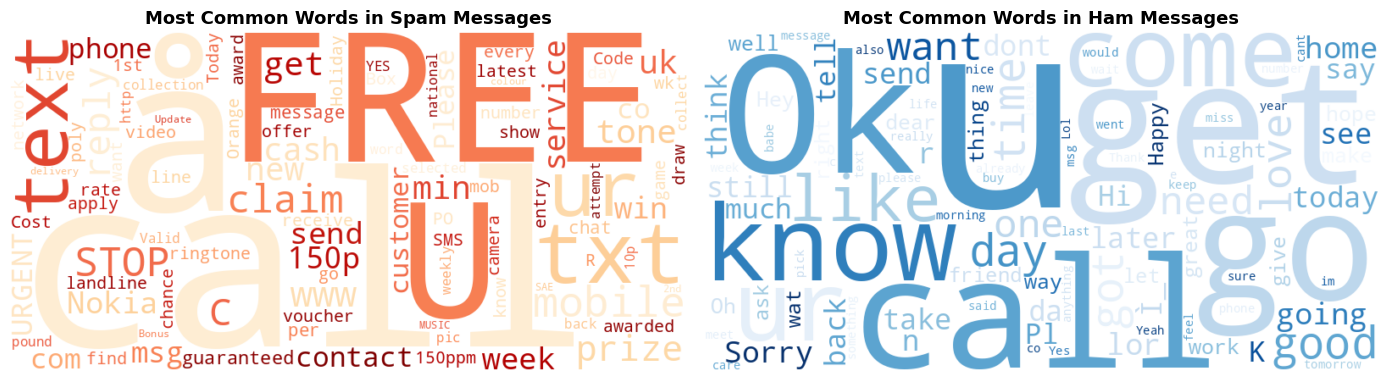

In [52]:
# Filter out stopwords and HTML artifacts (&lt;, &gt;, &amp;) common in this dataset
custom_stopwords = set(stopwords.words('english')).union({'gt', 'lt', 'amp'})

spam_text = ' '.join(df[df['label'] == 'spam']['message'])
ham_text = ' '.join(df[df['label'] == 'ham']['message'])

spam_wc = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=custom_stopwords,
    max_words=100,
    colormap='OrRd',
    collocations=False,
    random_state=42
).generate(spam_text)

ham_wc = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=custom_stopwords,
    max_words=100,
    colormap='Blues',
    collocations=False,
    random_state=42
).generate(ham_text)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(spam_wc, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Most Common Words in Spam Messages', fontsize=13, fontweight='bold')

axes[1].imshow(ham_wc, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Most Common Words in Ham Messages', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## Preprocessing

In [53]:
lemm = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()

    # Replace URLs and email addresses
    # Replace URLs and modern "click here" web prompts
    text = re.sub(r'http\S+|www\S+|click here|tap here', ' urltoken ', text)
    text = re.sub(r'\S+@\S+', ' emailtoken ', text)

    # Preserve currency symbols (£, $, €) as a word token
    text = re.sub(r'[£$€]', ' currencytoken ', text)

    # Separate 5+ digit phone/shortcode numbers from regular numbers
    text = re.sub(r'\b\d{5,}\b', ' phonetoken ', text)
    text = re.sub(r'\d+', ' numtoken ', text)

    # Keep letters and spam-related symbols (!, $, %, ?)
    text = re.sub(r'[^a-z!$%? ]', ' ', text)

    # Noun lemmatization preserves exact verb forms like "won" in "you have won"
    tokens = [
        lemm.lemmatize(word)
        for word in text.split()
    ]

    return ' '.join(tokens)


# Remove duplicate messages
df = df.drop_duplicates(subset=['label', 'message']).reset_index(drop=True).copy()

# Clean messages
df['clean_message'] = df['message'].apply(clean_text)

# Convert labels from text to numbers (safe if cell is re-run)
if df['label'].dtype == 'object':
    df['label'] = df['label'].map({'ham': 0, 'spam': 1})

df = df.dropna(subset=['label'])
df['label'] = df['label'].astype(int)

print("Dataset shape after deduplication:", df.shape)
print("\nLabel distribution (0 = Ham, 1 = Spam):")
print(df['label'].value_counts())

df.head()

Dataset shape after deduplication: (5158, 10)

Label distribution (0 = Ham, 1 = Spam):
label
0    4516
1     642
Name: count, dtype: int64


,label,message,char_count,word_count,digit_count,exclamation_count,question_count,currency_count,upper_ratio,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",111,20,0,0,0,0,0.026786,go until jurong point crazy available only in ...
1,0,Ok lar... Joking wif u oni...,29,6,0,0,0,0,0.066667,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,25,0,0,0,0.064103,free entry in numtoken a wkly comp to win fa c...
3,0,U dun say so early hor... U c already then say...,49,11,0,0,0,0,0.040000,u dun say so early hor u c already then say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,13,0,0,0,0,0.032258,nah i don t think he go to usf he life around ...


## Train/Test Split

In [54]:
# Input features and target
X = df['clean_message']
y = df['label']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 4126
Testing samples : 1032

Training label distribution:
label
0    3612
1     514
Name: count, dtype: int64

Testing label distribution:
label
0    904
1    128
Name: count, dtype: int64


## SVM Model

In [55]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=15000,
        ngram_range=(1, 3),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        strip_accents='unicode',
        token_pattern=r'(?u)\b\w\w+\b|[!$%?]'  # Preserves !, $, %, ? alongside words
    )),

    ('svm', LinearSVC(
        C=1.5,
        class_weight='balanced',
        random_state=42
    ))
])

pipeline.fit(X_train, y_train)

pred = pipeline.predict(X_test)

print("===== SVM Model Performance =====")
print(f"Accuracy : {accuracy_score(y_test, pred):.4f}")
print(f"Precision: {precision_score(y_test, pred):.4f}")
print(f"Recall   : {recall_score(y_test, pred):.4f}")
print(f"F1 Score : {f1_score(y_test, pred):.4f}")

print("\n===== Classification Report =====")
print(classification_report(
    y_test,
    pred,
    target_names=['Ham', 'Spam'],
    digits=4
))

===== SVM Model Performance =====
Accuracy : 0.9903
Precision: 0.9683
Recall   : 0.9531
F1 Score : 0.9606

===== Classification Report =====
              precision    recall  f1-score   support

         Ham     0.9934    0.9956    0.9945       904
        Spam     0.9683    0.9531    0.9606       128

    accuracy                         0.9903      1032
   macro avg     0.9808    0.9744    0.9776      1032
weighted avg     0.9903    0.9903    0.9903      1032



## Hyperparameter Tuning

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters:
{'svm__C': 0.5, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 3)}

Best Cross-Validation F1 Score: 0.9538

===== Tuned SVM Test Performance =====
Accuracy : 0.9903
Precision: 0.9609
Recall   : 0.9609
F1 Score : 0.9609


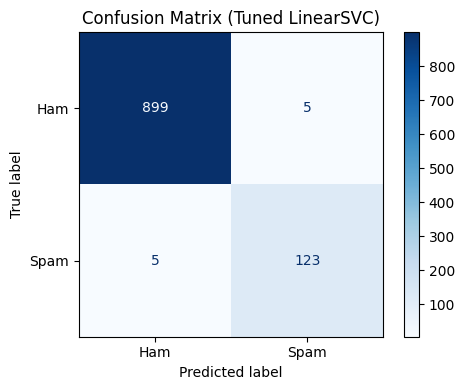

In [56]:
param_grid = {
    'tfidf__max_features': [10000, 15000],
    'tfidf__ngram_range': [(1, 2), (1, 3)],
    'svm__C': [0.5, 1.0, 1.5, 2.0]
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)
print(f"\nBest Cross-Validation F1 Score: {grid.best_score_:.4f}")

# Evaluate the tuned model on the test set
best_svm = grid.best_estimator_
tuned_pred = best_svm.predict(X_test)

print("\n===== Tuned SVM Test Performance =====")
print(f"Accuracy : {accuracy_score(y_test, tuned_pred):.4f}")
print(f"Precision: {precision_score(y_test, tuned_pred):.4f}")
print(f"Recall   : {recall_score(y_test, tuned_pred):.4f}")
print(f"F1 Score : {f1_score(y_test, tuned_pred):.4f}")

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_pred,
    display_labels=['Ham', 'Spam'],
    cmap='Blues',
    values_format='d',
    ax=ax
)
plt.title('Confusion Matrix (Tuned LinearSVC)')
plt.tight_layout()
plt.show()

## Cross Validation

===== 5-Fold Stratified Cross-Validation =====
Fold 1 F1 Score: 0.9606
Fold 2 F1 Score: 0.9402
Fold 3 F1 Score: 0.9603
Fold 4 F1 Score: 0.9650
Fold 5 F1 Score: 0.9653

Mean F1 Score     : 0.9583
Standard Deviation: 0.0093


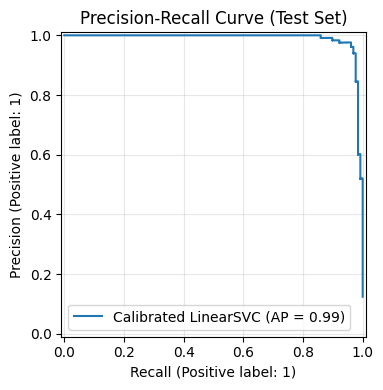

In [57]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    grid.best_estimator_,
    df['clean_message'],
    df['label'],
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

print("===== 5-Fold Stratified Cross-Validation =====")
for i, score in enumerate(scores, 1):
    print(f"Fold {i} F1 Score: {score:.4f}")

print(f"\nMean F1 Score     : {scores.mean():.4f}")
print(f"Standard Deviation: {scores.std():.4f}")

# Calibrate the best SVM model to get probability confidence scores
calibrated_model = CalibratedClassifierCV(estimator=grid.best_estimator_, cv=cv, n_jobs=-1)
calibrated_model.fit(X_train, y_train)

# Plot Precision-Recall Curve
fig, ax = plt.subplots(figsize=(6, 4))
PrecisionRecallDisplay.from_estimator(
    calibrated_model,
    X_test,
    y_test,
    name='Calibrated LinearSVC',
    ax=ax
)
plt.title('Precision-Recall Curve (Test Set)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Prediction Function

In [59]:
# Use the best model found by GridSearchCV
model = grid.best_estimator_

def predict_sms(text):
    cleaned_text = clean_text(text)
    prediction = model.predict([cleaned_text])[0]
    spam_prob = calibrated_model.predict_proba([cleaned_text])[0][1]

    label = "SPAM" if prediction == 1 else "HAM"
    confidence = spam_prob if prediction == 1 else (1 - spam_prob)

    return f"{label} (Confidence: {confidence * 100:.2f}%)"


# Test messages
test_messages = [
    "Congratulations! You have won a free iPhone. Click here now.",
    "Hi, are we meeting tomorrow at 3 PM?",
    "URGENT! You have won $1000. Call now!",
    "Can you send me the assignment notes?",
    "Free entry to win a cash prize! Reply NOW!",
    "Your appointment is confirmed for tomorrow.",
    "URGENT: Your bank account has been temporarily locked due to suspicious activity. Verify your identity now."
]

# Display predictions
for message in test_messages:
    print("Message   :", message)
    print("Prediction:", predict_sms(message))
    print("-" * 60)

Message   : Congratulations! You have won a free iPhone. Click here now.
Prediction: SPAM (Confidence: 94.71%)
------------------------------------------------------------
Message   : Hi, are we meeting tomorrow at 3 PM?
Prediction: HAM (Confidence: 99.45%)
------------------------------------------------------------
Message   : URGENT! You have won $1000. Call now!
Prediction: SPAM (Confidence: 96.70%)
------------------------------------------------------------
Message   : Can you send me the assignment notes?
Prediction: HAM (Confidence: 99.86%)
------------------------------------------------------------
Message   : Free entry to win a cash prize! Reply NOW!
Prediction: SPAM (Confidence: 96.65%)
------------------------------------------------------------
Message   : Your appointment is confirmed for tomorrow.
Prediction: HAM (Confidence: 96.31%)
------------------------------------------------------------
Message   : URGENT: Your bank account has been temporarily locked due to sus